House Price Prediction — Machine Learning Project
Project Objective
The objective is to predict residential house selling prices using property-related features such as house quality, living area, location, number of bedrooms, bathrooms, garage size, and year of construction.

This project evaluates different machine learning regression algorithms to identify the most effective model for predicting house prices.

This project focuses on two stages of model development:
1. Baseline Regression Prediction:
   Predicts house selling prices using basic regression algorithms such as Linear Regression, Decision Tree Regression, and K-Nearest Neighbors Regression.
2. Advanced Regression Prediction:
   Improves prediction performance using ensemble learning algorithms such as Random Forest and Gradient Boosting/XGBoost, along with hyperparameter tuning and cross-validation.
Note: House Price Prediction is a supervised regression problem because the target variable (SalePrice) is continuous. Classification algorithms are not applicable.
Project Workflow
Week	Activities
Week 1	Problem understanding, dataset collection, EDA, missing value analysis, outlier detection, feature encoding, baseline regression models
Week 2	Random Forest, Gradient Boosting, XGBoost, GridSearchCV, cross-validation, residual analysis, feature importance
Week 4	Model selection, performance comparison, feature importance interpretation, business insights, limitations, future improvements and deployment


Methodology
- Target Variable: SalePrice
- Problem Type: Supervised Machine Learning – Regression
- Dataset: House Prices – Advanced Regression Techniques
- Training Dataset: 1460 records
- Testing Dataset: 1459 records
- Total Features: 79 explanatory variables
- Train-Test Split: 70:30 (train / held-out validation)
- Evaluation Metrics: MAE, RMSE and R² Score
- Validation: Cross-validation using appropriate validation strategy
- Feature Engineering: Missing value treatment, categorical encoding and numerical feature preprocessing.
Important: The dataset's SalePrice column is available only in the training dataset. It must not be used as an input feature.

## How to run this notebook
1. Place `train.csv` and `test.csv` (Kaggle *House Prices: Advanced Regression Techniques*) next to this notebook, or upload them to the Colab session (`/content`).
2. Run **Runtime / Kernel → Restart and run all**. Every number, chart and written interpretation below is generated from the actual run, so nothing needs to be edited by hand.
3. Full run time is roughly 5–10 minutes (cross-validation and two grid searches).
4. Save the notebook **with outputs** before submitting.

# WEEK 1 — Problem Understanding, Data Exploration & Baseline Modeling

## 1.1 Business / Scientific Problem
House prices depend on several factors, including location, property size, construction quality, number of rooms, garage facilities and overall condition. The objective is to build a supervised **regression** model that predicts the sale price (`SalePrice`) of a residential property from its available features.

## 1.2 Dataset
This notebook uses the Kaggle House Prices: Advanced Regression Techniques dataset. The training file contains the target variable `SalePrice`; the separate test file does not contain target labels and is reserved for final predictions.

## 1.3 Week 1 activities
- Understand the problem, dataset dimensions, feature types and target.
- Analyze missing values, distributions, outliers and correlations.
- Apply appropriate preprocessing and feature encoding.
- Split the labelled data into **70% training and 30% validation/test** using a fixed random seed.
- Implement baseline Linear Regression, Decision Tree Regressor and KNN Regressor.
- Compare models using MAE, RMSE and R² (RMSLE is included as an additional metric for this positive-price target).

# WEEK 2 — Advanced Modeling, Optimization & Interpretation

## 2.1 Advanced regression algorithms
- Random Forest Regressor
- Gradient Boosting Regressor
- XGBoost Regressor

## 2.2 Optimization and validation
- Apply GridSearchCV using cross-validation on the training partition only.
- Select hyperparameters using a documented scoring metric.
- Evaluate the tuned model once on the held-out 30% validation partition.

## 2.3 Regression-specific analysis
- Analyze residuals using a residual histogram and residuals-versus-predicted plot.
- Explain feature importance for the selected tree-based model.
- Compare baseline and tuned model performance.

# WEEK 4 — Interpretation, Documentation & Deployment Insights

The final report and presentation should include:
- Final model selection and justification using held-out validation metrics.
- Feature importance and what the important features mean for house prices.
- Business insights supported by EDA and model results.
- Model limitations, risks and possible sources of prediction error.
- Future improvements, such as richer location data, robust validation, improved feature engineering and model monitoring.
- Optional: a simple Streamlit or Flask demonstration.

**Final deliverables:** Jupyter Notebook (`.ipynb`), 6–8 page technical report and 10–12 minute presentation. The separate 2–3 page EDA summary can be included as an early section/appendix of the technical report if the instructor expects both.

In [34]:
# Data manipulation
import os
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Machine learning
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Saving the final model (used by the optional demo app)
import joblib

import warnings
warnings.filterwarnings('ignore')

# Plot settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42
print("All libraries imported successfully!")

All libraries imported successfully!


In [35]:
def find_file(name):
    candidates = [
        name,
        f'/content/{name}',
        f'/kaggle/input/house-prices-advanced-regression-techniques/{name}',
        f'data/{name}',
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        f"Could not find {name}. Upload it next to the notebook (or into /content on Colab)."
    )

train = pd.read_csv(find_file('train.csv'))
test = pd.read_csv(find_file('test.csv'))

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

print("\nFirst 5 Rows:")
display(train.head())

Training Dataset Shape: (1460, 81)
Testing Dataset Shape: (1459, 80)

First 5 Rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [36]:
print("Dataset Information:")
print(train.info())

print("\nStatistical Summary:")
display(train.describe())

print("\nDataset Columns:")
print(train.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



Dataset Columns:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'P

### Dataset and Target Summary

In [37]:
print(f"Training dataset: {train.shape[0]} rows × {train.shape[1]} columns")
print(f"Unlabelled Kaggle test dataset: {test.shape[0]} rows × {test.shape[1]} columns")
print("Target variable: SalePrice (continuous numerical variable; regression)")
print("\nFeature data types:")
display(train.drop(columns=['SalePrice']).dtypes.value_counts().rename_axis('Data type').to_frame('Column count'))
print("\nTarget summary:")
display(train['SalePrice'].describe())

Training dataset: 1460 rows × 81 columns
Unlabelled Kaggle test dataset: 1459 rows × 80 columns
Target variable: SalePrice (continuous numerical variable; regression)

Feature data types:


,Column count
Data type,
object,43
int64,34
float64,3



Target summary:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


### 1.2 Missing Value Analysis

19 of 81 columns contain missing values.


,Missing Count,Missing %
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


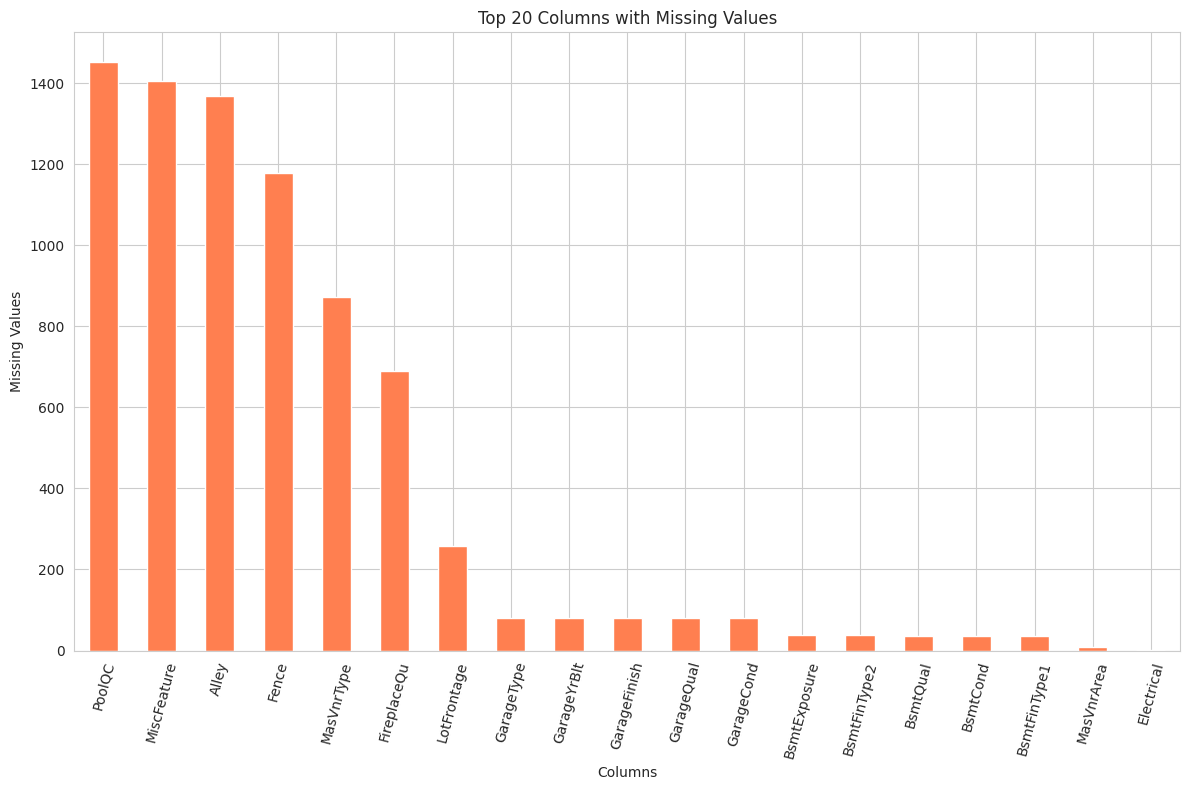

In [38]:
missing_count = train.isnull().sum()
missing_table = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %': (100 * missing_count / len(train)).round(2)
})
missing_table = missing_table[missing_table['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

print(f"{len(missing_table)} of {train.shape[1]} columns contain missing values.")
display(missing_table)

plt.figure(figsize=(12, 8))
missing_table['Missing Count'].head(20).plot(kind='bar', color='coral')
plt.title("Top 20 Columns with Missing Values")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Interpretation.** In this dataset many "missing" values are **not data errors**: for columns such as `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `GarageType` and the `Bsmt*` columns, a blank means the house simply *has no* pool / fireplace / garage / basement. Replacing them with the most frequent category would destroy that information, so categorical blanks are filled with an explicit `'None'` category. For numeric columns, `MasVnrArea` and `GarageYrBlt` are blank when there is no veneer / garage, so they are filled with `0`; the remaining numeric blanks (mainly `LotFrontage`) use the median as a baseline.

### 1.3 Distribution Analysis

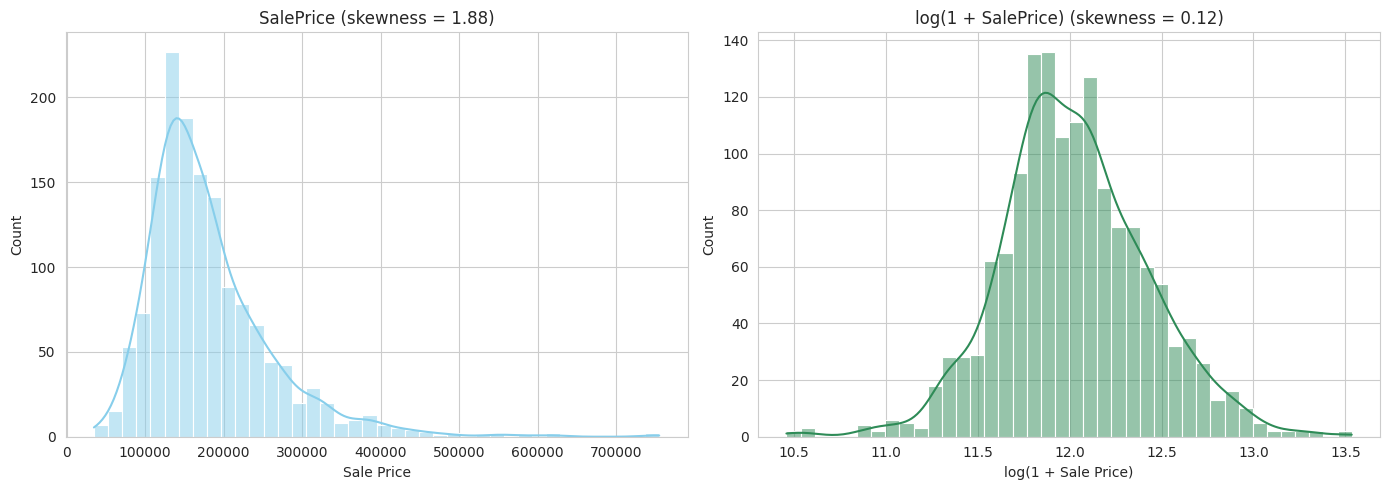

SalePrice skewness: 1.88  ->  after log transform: 0.12


In [39]:
# --- Target distribution: raw vs log-transformed -------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train['SalePrice'], kde=True, bins=40, color='skyblue', ax=axes[0])
axes[0].set_title(f"SalePrice (skewness = {train['SalePrice'].skew():.2f})")
axes[0].set_xlabel("Sale Price")

sns.histplot(np.log1p(train['SalePrice']), kde=True, bins=40, color='seagreen', ax=axes[1])
axes[1].set_title(f"log(1 + SalePrice) (skewness = {np.log1p(train['SalePrice']).skew():.2f})")
axes[1].set_xlabel("log(1 + Sale Price)")

plt.tight_layout()
plt.show()

print(f"SalePrice skewness: {train['SalePrice'].skew():.2f}  ->  after log transform: {np.log1p(train['SalePrice']).skew():.2f}")

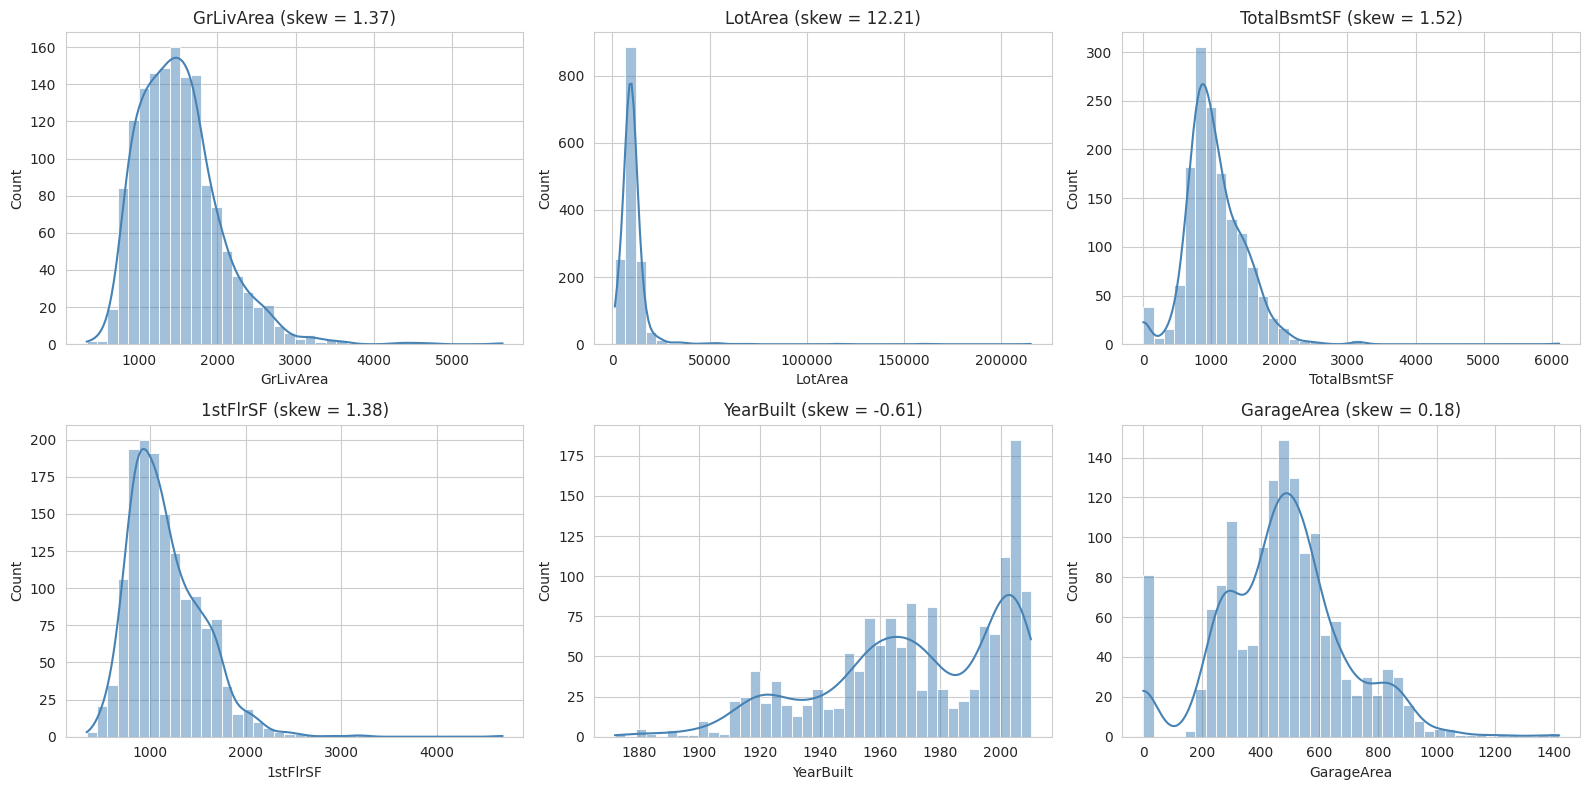

Ten most right-skewed numeric features:


,Skewness
MiscVal,24.48
PoolArea,14.83
LotArea,12.21
3SsnPorch,10.30
LowQualFinSF,9.01
KitchenAbvGr,4.49
BsmtFinSF2,4.26
ScreenPorch,4.12
BsmtHalfBath,4.10
EnclosedPorch,3.09


In [40]:
# --- Distribution of key numeric predictors ------------------------------------------
key_numeric = [c for c in ['GrLivArea', 'LotArea', 'TotalBsmtSF', '1stFlrSF', 'YearBuilt', 'GarageArea']
               if c in train.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.histplot(train[col].dropna(), kde=True, bins=40, ax=ax, color='steelblue')
    ax.set_title(f"{col} (skew = {train[col].skew():.2f})")
for ax in axes.ravel()[len(key_numeric):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

# --- Skewness table for all numeric features ------------------------------------------
skew_table = (train.select_dtypes(include=[np.number])
              .drop(columns=['Id'], errors='ignore')
              .skew()
              .sort_values(ascending=False)
              .rename('Skewness')
              .to_frame())
print("Ten most right-skewed numeric features:")
display(skew_table.head(10).round(2))

**Interpretation.** `SalePrice` is right-skewed: most houses sell in a moderate range while a few expensive properties form a long tail. A log transform makes the distribution much closer to symmetric, which is why **RMSLE** (the error on the log scale) is reported as an extra metric. Several area variables (`LotArea`, `GrLivArea`, `TotalBsmtSF`) are also right-skewed. Tree-based models are insensitive to this skewness, while Linear Regression and KNN can be affected by it; this is kept in mind when comparing models.

### 1.4 Correlation Analysis

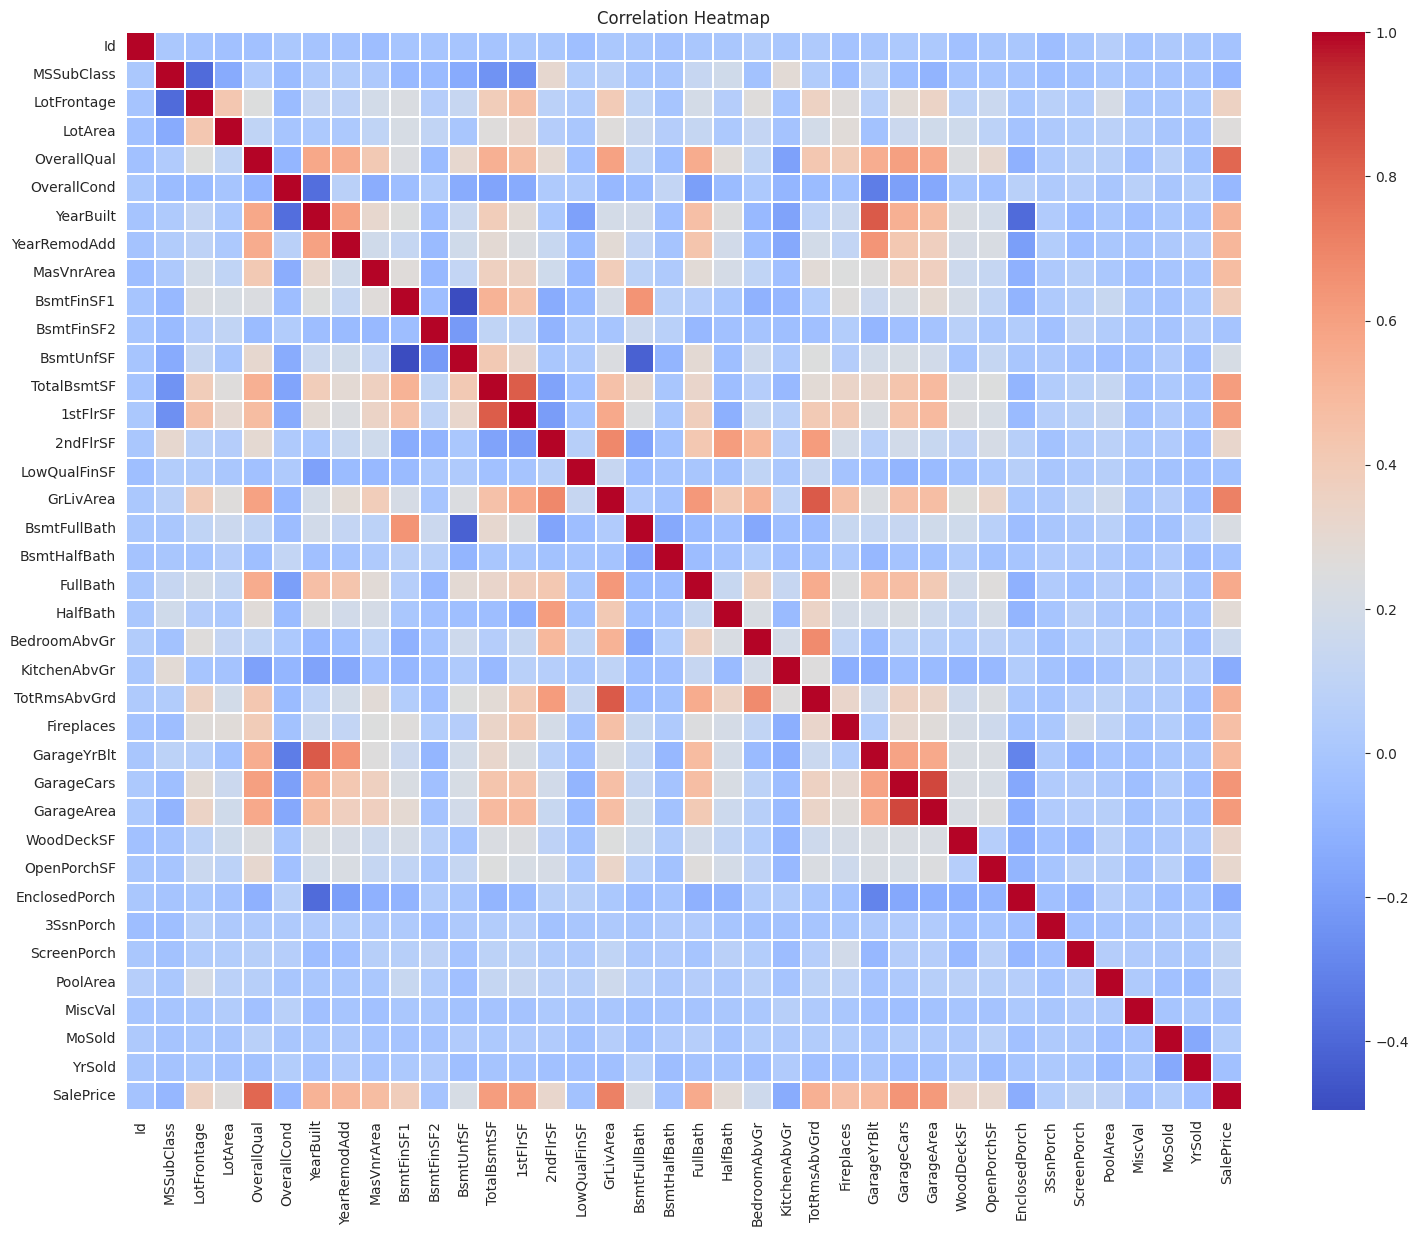

In [41]:
numeric_data = train.select_dtypes(
    include=[np.number]
)

correlation = numeric_data.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap")

plt.show()

Top 15 Features Related to House Price:


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


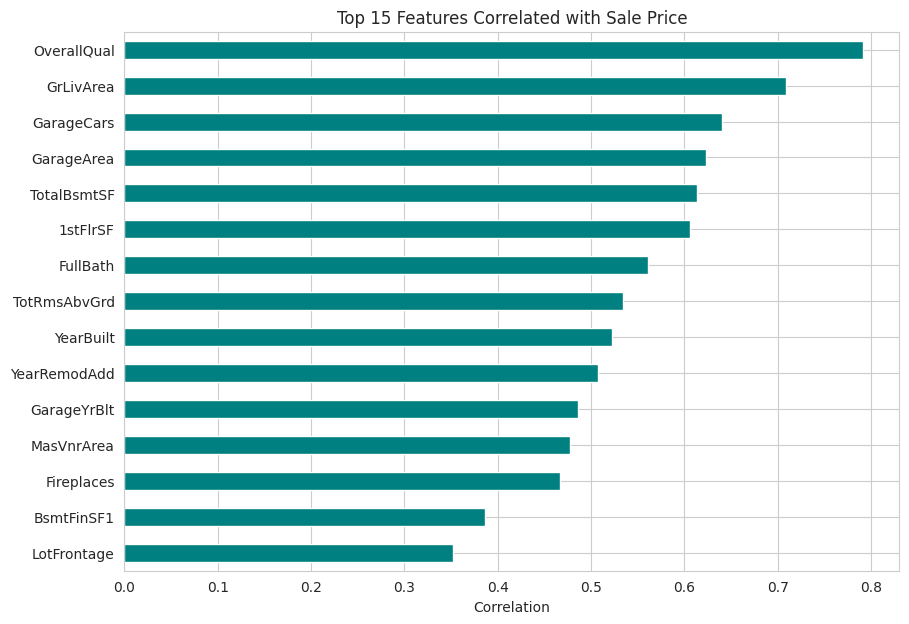

In [42]:
price_corr = correlation['SalePrice'].sort_values(
    ascending=False
)

print("Top 15 Features Related to House Price:")

display(price_corr.head(16))

plt.figure(figsize=(10, 7))

price_corr.head(16).drop(
    'SalePrice'
).sort_values().plot(
    kind='barh',
    color='teal'
)

plt.title("Top 15 Features Correlated with Sale Price")
plt.xlabel("Correlation")

plt.show()

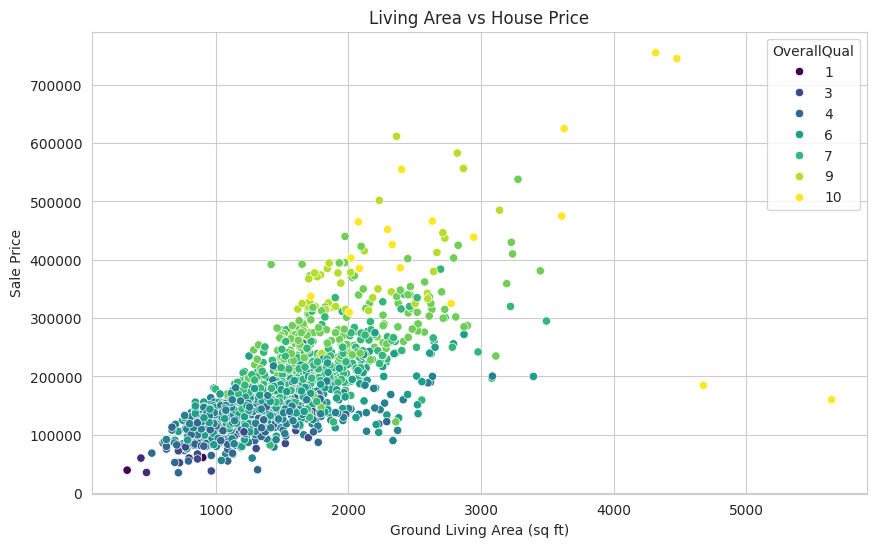

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train,
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    palette='viridis'
)

plt.title("Living Area vs House Price")
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()

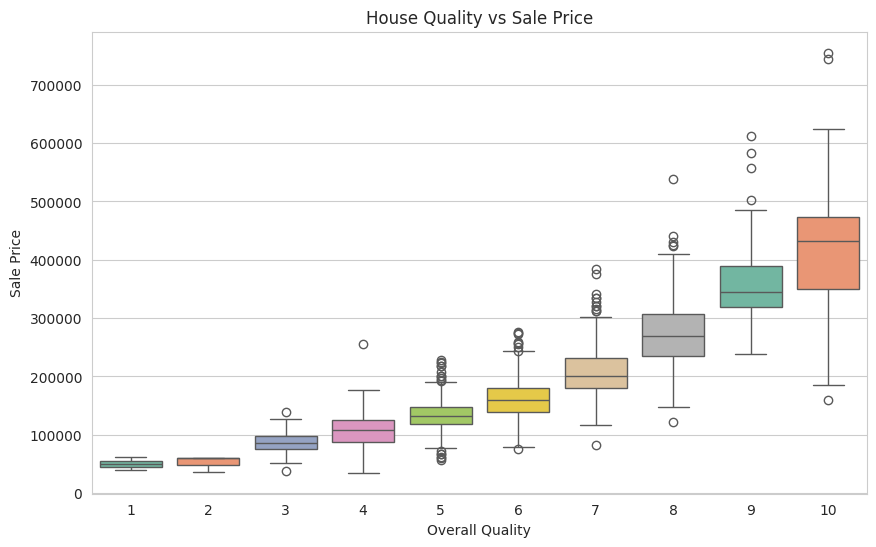

In [44]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train,
    x='OverallQual',
    y='SalePrice',
    palette='Set2'
)

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

### 1.5 Outlier Detection

Boxplots, scatterplots and the IQR rule help identify unusually high or low observations. Outliers are **investigated rather than automatically deleted**: a high-priced or unusually large house may be a genuine property.

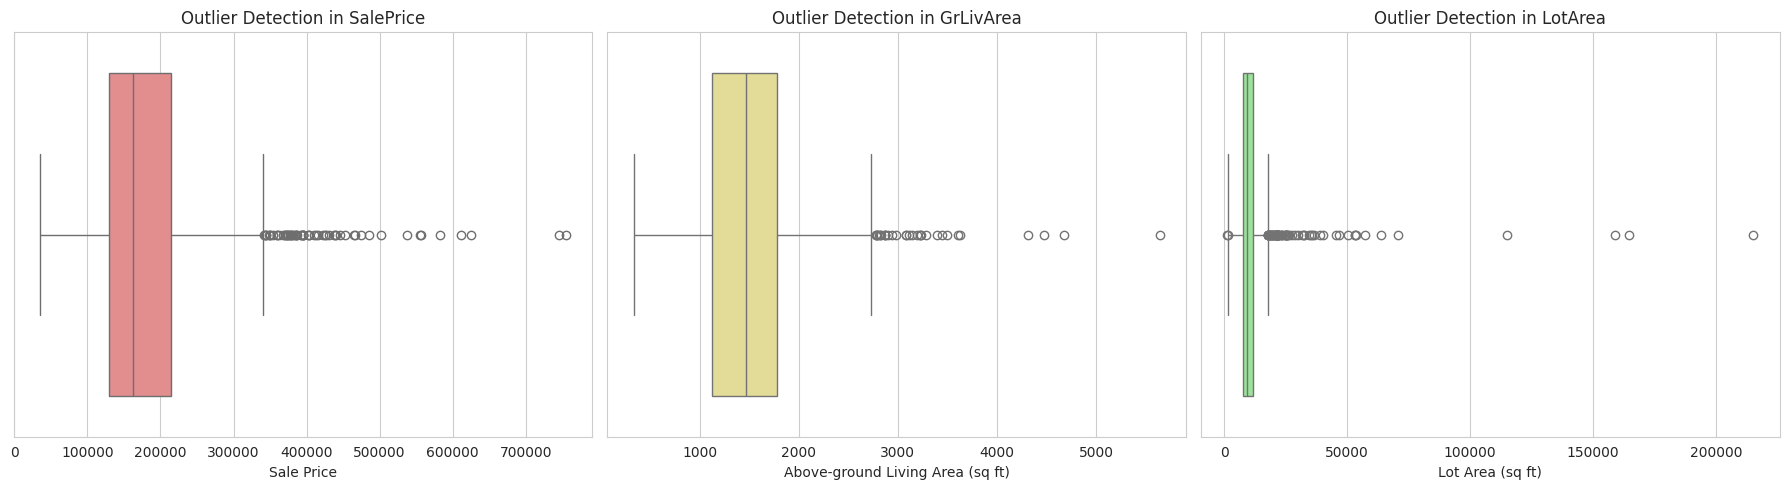

,Feature,Lower fence,Upper fence,Outliers,% of rows
0,SalePrice,3938,340038,61,4.18
1,GrLivArea,159,2748,31,2.12
2,LotArea,1482,17674,69,4.73


In [45]:
# Boxplots of the target and two key numeric predictors
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x=train['SalePrice'], ax=axes[0], color='lightcoral')
axes[0].set_title('Outlier Detection in SalePrice')
axes[0].set_xlabel('Sale Price')
sns.boxplot(x=train['GrLivArea'], ax=axes[1], color='khaki')
axes[1].set_title('Outlier Detection in GrLivArea')
axes[1].set_xlabel('Above-ground Living Area (sq ft)')
sns.boxplot(x=train['LotArea'], ax=axes[2], color='lightgreen')
axes[2].set_title('Outlier Detection in LotArea')
axes[2].set_xlabel('Lot Area (sq ft)')
plt.tight_layout()
plt.show()

# IQR rule: how many observations fall outside Q1 - 1.5*IQR and Q3 + 1.5*IQR?
rows = []
for col in ['SalePrice', 'GrLivArea', 'LotArea']:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((train[col] < low) | (train[col] > high)).sum()
    rows.append({'Feature': col, 'Lower fence': round(low), 'Upper fence': round(high),
                 'Outliers': n_out, '% of rows': round(100 * n_out / len(train), 2)})
display(pd.DataFrame(rows))

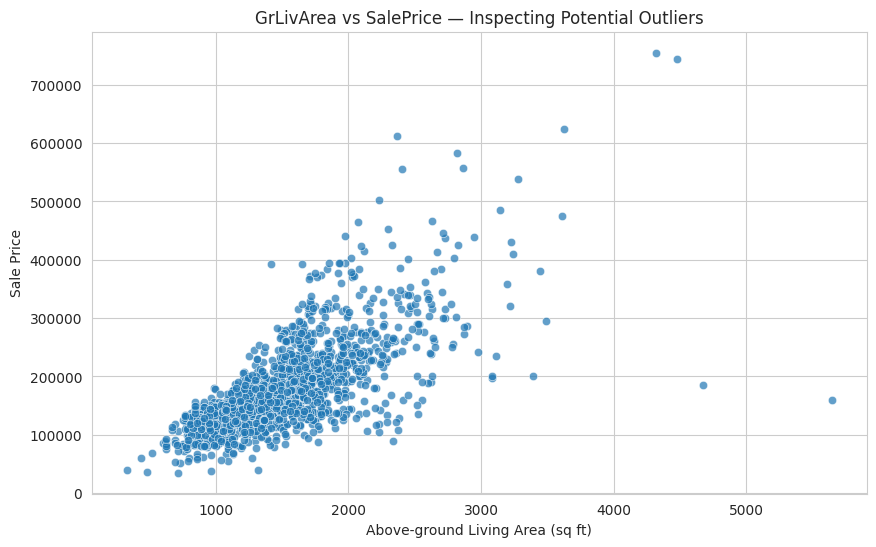

Largest living-area houses (manual inspection):


,Id,GrLivArea,OverallQual,SalePrice
1298,1299,5642,10,160000
523,524,4676,10,184750
1182,1183,4476,10,745000
691,692,4316,10,755000
1169,1170,3627,10,625000
185,186,3608,10,475000
304,305,3493,7,295000
1268,1269,3447,8,381000
635,636,3395,6,200000
769,770,3279,8,538000


In [46]:
# Inspect potentially influential observations in living area
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice', alpha=0.7)
plt.title('GrLivArea vs SalePrice — Inspecting Potential Outliers')
plt.xlabel('Above-ground Living Area (sq ft)')
plt.ylabel('Sale Price')
plt.show()

print("Largest living-area houses (manual inspection):")
display(
    train[['Id', 'GrLivArea', 'OverallQual', 'SalePrice']]
    .sort_values('GrLivArea', ascending=False)
    .head(10)
)

**Decision on outliers.** The IQR rule flags a number of expensive houses and large lots, but these are genuine sales in a market with a few luxury properties, so they are **kept**. The scatterplot shows a few houses with a very large living area but an unusually low price (partial / unusual sales); they are a recognised quirk of this dataset. They are **not removed** here so that the validation results remain an honest estimate of performance on unseen data, and their influence is discussed in the limitations section.

### 1.6 Feature Preparation and Encoding

In [47]:
X = train.drop(
    ['SalePrice', 'Id'],
    axis=1
)

y = train['SalePrice']

test_ids = test['Id']

X_test_final = test.drop(
    ['Id'],
    axis=1
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1460, 79)
Target Shape: (1460,)


In [48]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 36
Categorical Features: 43


In [49]:
# Numerical columns that are blank because the feature does not exist -> 0
zero_fill_features = [c for c in ['MasVnrArea', 'GarageYrBlt'] if c in numeric_features]
# All other numerical columns (e.g. LotFrontage) -> median imputation
other_numeric_features = [c for c in numeric_features if c not in zero_fill_features]

print("Zero-filled numeric features:", zero_fill_features)
print("Median-imputed numeric features:", len(other_numeric_features))

other_numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

zero_numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
        ('scaler', StandardScaler())
    ]
)

# Categorical columns: keep missing values as an explicit category.
# For structural fields (pool / garage / basement ...), missing means "no such feature".
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', other_numeric_transformer, other_numeric_features),
        ('zero', zero_numeric_transformer, zero_fill_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Zero-filled numeric features: ['MasVnrArea', 'GarageYrBlt']
Median-imputed numeric features: 34
Preprocessing Pipeline Created Successfully!


### 1.7 Train / Validation Split (70% / 30%)

In [50]:
# Required assignment split: 70% training and 30% held-out validation/test.
# The held-out partition is used only for final model comparison, never for fitting or tuning.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

print("Training Records:", X_train.shape[0])
print("Validation Records:", X_val.shape[0])
print(f"Training Percentage: {100 * len(X_train) / len(X):.1f}%")
print(f"Validation Percentage: {100 * len(X_val) / len(X):.1f}%")
print(f"\nNote: the {len(test)}-row Kaggle test file has no SalePrice labels and is used only for the final predictions.")

Training Records: 1022
Validation Records: 438
Training Percentage: 70.0%
Validation Percentage: 30.0%

Note: the 1459-row Kaggle test file has no SalePrice labels and is used only for the final predictions.


## Model Evaluation Function

In [51]:
def evaluate_model(model, X_train, X_val, y_train, y_val, name=None):
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)

    # SalePrice is non-negative; clip negative predictions so log-based RMSLE is defined.
    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)
    rmsle = np.sqrt(mean_squared_error(np.log1p(y_val), np.log1p(predictions)))

    # Report a readable algorithm name instead of the outer Pipeline class.
    estimator_name = name if name else model.named_steps['model'].__class__.__name__

    return {
        'Model': estimator_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2,
        'RMSLE': rmsle
    }

## Baseline Regression Models

### Baseline Model 1 — Linear Regression

In [52]:
linear_model = Pipeline(steps=[('preprocessor', preprocessor), ('model', LinearRegression())])
linear_results = evaluate_model(linear_model, X_train, X_val, y_train, y_val, name='Linear Regression')
print(linear_results)

{'Model': 'Linear Regression', 'MAE': 20675.13446394211, 'RMSE': np.float64(61734.541133617815), 'R2 Score': 0.4538403037357097, 'RMSLE': np.float64(0.6045590720928873)}


### Baseline Model 2 — Decision Tree Regressor

In [53]:
decision_model = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE))]
)
decision_results = evaluate_model(decision_model, X_train, X_val, y_train, y_val, name='Decision Tree')
print(decision_results)

{'Model': 'Decision Tree', 'MAE': 25580.73938551922, 'RMSE': np.float64(42530.979649055575), 'R2 Score': 0.7407767376194025, 'RMSLE': np.float64(0.20642782616835584)}


### Baseline Model 3 — K-Nearest Neighbors Regressor

KNN predicts a house price using the target values of the most similar houses in the training data. Scaling is important for distance-based KNN, so the numerical preprocessing pipeline includes `StandardScaler`.

In [54]:
knn_model = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', KNeighborsRegressor(n_neighbors=5, weights='distance'))]
)
knn_results = evaluate_model(knn_model, X_train, X_val, y_train, y_val, name='KNN')
print(knn_results)

{'Model': 'KNN', 'MAE': 21651.194888409507, 'RMSE': np.float64(36614.14296313235), 'R2 Score': 0.8078851458791176, 'RMSLE': np.float64(0.17257045153850883)}


### Baseline Model Comparison and Interpretation

In [55]:
baseline_table = pd.DataFrame([linear_results, decision_results, knn_results])
print("BASELINE MODEL COMPARISON (held-out 30% validation set)")
display(baseline_table.sort_values('RMSE').round(4).reset_index(drop=True))

best_b = baseline_table.loc[baseline_table['RMSE'].idxmin()]
worst_b = baseline_table.loc[baseline_table['RMSE'].idxmax()]

print("\nINTERPRETATION")
print(f"Among the three baseline models, {best_b['Model']} performed best with an R2 of {best_b['R2 Score']:.3f}, "
      f"an MAE of about ${best_b['MAE']:,.0f} and an RMSE of about ${best_b['RMSE']:,.0f}. "
      f"{worst_b['Model']} performed worst (R2 = {worst_b['R2 Score']:.3f}, RMSE = ${worst_b['RMSE']:,.0f}), "
      f"i.e. its typical error is ${worst_b['RMSE'] - best_b['RMSE']:,.0f} larger.")
print(f"RMSE is larger than MAE for every model, which shows that a few houses (mostly expensive ones) are predicted "
      f"much worse than the rest, because RMSE penalises large errors more heavily.")
print("These baselines are simple: Linear Regression assumes straight-line relationships, a single Decision Tree is "
      "unstable (high variance), and KNN relies on distances that become less informative with many one-hot columns. "
      "The ensemble models below are expected to reduce these weaknesses.")

BASELINE MODEL COMPARISON (held-out 30% validation set)


,Model,MAE,RMSE,R2 Score,RMSLE
0,KNN,21651.1949,36614.1430,0.8079,0.1726
1,Decision Tree,25580.7394,42530.9796,0.7408,0.2064
2,Linear Regression,20675.1345,61734.5411,0.4538,0.6046



INTERPRETATION
Among the three baseline models, KNN performed best with an R2 of 0.808, an MAE of about $21,651 and an RMSE of about $36,614. Linear Regression performed worst (R2 = 0.454, RMSE = $61,735), i.e. its typical error is $25,120 larger.
RMSE is larger than MAE for every model, which shows that a few houses (mostly expensive ones) are predicted much worse than the rest, because RMSE penalises large errors more heavily.
These baselines are simple: Linear Regression assumes straight-line relationships, a single Decision Tree is unstable (high variance), and KNN relies on distances that become less informative with many one-hot columns. The ensemble models below are expected to reduce these weaknesses.


## Advanced Regression Models

### Random Forest

In [56]:
random_forest_model = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_split=2,
                                           random_state=RANDOM_STATE, n_jobs=-1))]
)
random_forest_results = evaluate_model(random_forest_model, X_train, X_val, y_train, y_val, name='Random Forest')
print(random_forest_results)

{'Model': 'Random Forest', 'MAE': 16718.10843036727, 'RMSE': np.float64(26822.102356147614), 'R2 Score': 0.8969023347277554, 'RMSLE': np.float64(0.14003897849985186)}


### Gradient Boosting

In [57]:
gradient_model = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                               random_state=RANDOM_STATE))]
)
gradient_results = evaluate_model(gradient_model, X_train, X_val, y_train, y_val, name='Gradient Boosting')
print(gradient_results)

{'Model': 'Gradient Boosting', 'MAE': 15648.19159624439, 'RMSE': np.float64(25706.39663865212), 'R2 Score': 0.9053009531280999, 'RMSLE': np.float64(0.12840996350975242)}


### XGBoost

In [58]:
xgb_model = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8,
                                  colsample_bytree=0.8, objective='reg:squarederror',
                                  random_state=RANDOM_STATE, n_jobs=-1))]
)
xgb_results = evaluate_model(xgb_model, X_train, X_val, y_train, y_val, name='XGBoost')
print(xgb_results)

{'Model': 'XGBoost', 'MAE': 14656.61328125, 'RMSE': np.float64(22856.68952407588), 'R2 Score': 0.9251331090927124, 'RMSLE': np.float64(0.1273374105264259)}


## Cross-Validation of All Models

A single 70/30 split can be lucky or unlucky. **5-fold K-Fold cross-validation** is therefore run on the 70% training partition for every model, giving a more reliable estimate of how well each model generalises (mean and standard deviation across folds). The 30% validation partition is not used here.

In [59]:
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_for_cv = {
    'Linear Regression': linear_model,
    'Decision Tree': decision_model,
    'KNN': knn_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_model,
    'XGBoost': xgb_model,
}

cv_rows = []
for name, mdl in models_for_cv.items():
    scores = cross_validate(
        mdl, X_train, y_train, cv=cv_strategy,
        scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
        n_jobs=1
    )
    cv_rows.append({
        'Model': name,
        'CV RMSE (mean)': -scores['test_rmse'].mean(),
        'CV RMSE (std)': scores['test_rmse'].std(),
        'CV R2 (mean)': scores['test_r2'].mean(),
    })
    print(f"{name:20s} CV RMSE = {-scores['test_rmse'].mean():>10,.0f} (+/- {scores['test_rmse'].std():,.0f})")

cv_table = pd.DataFrame(cv_rows)
print("\n5-FOLD CROSS-VALIDATION RESULTS (training partition only)")
display(cv_table.sort_values('CV RMSE (mean)').round(4).reset_index(drop=True))

Linear Regression    CV RMSE =     67,237 (+/- 32,881)
Decision Tree        CV RMSE =     42,026 (+/- 8,542)
KNN                  CV RMSE =     38,631 (+/- 8,715)
Random Forest        CV RMSE =     31,479 (+/- 5,946)
Gradient Boosting    CV RMSE =     29,879 (+/- 4,988)
XGBoost              CV RMSE =     30,200 (+/- 6,214)

5-FOLD CROSS-VALIDATION RESULTS (training partition only)


,Model,CV RMSE (mean),CV RMSE (std),CV R2 (mean)
0,Gradient Boosting,29879.1263,4987.6011,0.8458
1,XGBoost,30200.2141,6214.1061,0.8421
2,Random Forest,31478.6275,5945.5974,0.8282
3,KNN,38631.4632,8714.8722,0.7480
4,Decision Tree,42025.6770,8541.8811,0.6815
5,Linear Regression,67236.8448,32881.1017,-0.2500


## Hyperparameter Tuning with GridSearchCV

GridSearchCV tests a defined set of hyperparameter combinations. Five-fold cross-validation is applied **only within the 70% training partition**, so the 30% held-out validation data stays unseen during tuning. Preprocessing is kept **inside** the Pipeline so that imputation, scaling and encoding are re-fitted within each fold (no leakage). Two models are tuned, **Random Forest** and **XGBoost**, using negative RMSE as the scoring metric; each best estimator is then evaluated once on the held-out validation partition.

In [60]:
# ----- XGBoost -----
xgb_pipeline_for_tuning = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', XGBRegressor(objective='reg:squarederror', subsample=0.8, colsample_bytree=0.8,
                                  random_state=RANDOM_STATE, n_jobs=1))]
)

xgb_param_grid = {
    'model__n_estimators': [500, 1000],
    'model__learning_rate': [0.03, 0.05],
    'model__max_depth': [3, 4]
}

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline_for_tuning,
    param_grid=xgb_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)
xgb_grid.fit(X_train, y_train)

print("XGBoost - Best Parameters:", xgb_grid.best_params_)
print(f"XGBoost - Best Mean CV RMSE: {-xgb_grid.best_score_:,.0f}")

tuned_xgb_model = xgb_grid.best_estimator_
tuned_xgb_results = evaluate_model(tuned_xgb_model, X_train, X_val, y_train, y_val, name='XGBoost (Tuned)')
print("Tuned XGBoost Validation Results:")
print(tuned_xgb_results)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
XGBoost - Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 1000}
XGBoost - Best Mean CV RMSE: 29,753
Tuned XGBoost Validation Results:
{'Model': 'XGBoost (Tuned)', 'MAE': 15019.298828125, 'RMSE': np.float64(23841.328822026677), 'R2 Score': 0.918543815612793, 'RMSLE': np.float64(0.13035786118025855)}


In [61]:
from sklearn.ensemble import RandomForestRegressor

# ----- Random Forest Grid Search Setup and Fit -----
rf_pipeline_for_tuning = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]
)

rf_param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 15],
    'model__min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline_for_tuning,
    param_grid=rf_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

print("Fitting Random Forest Grid Search...")
rf_grid.fit(X_train, y_train)
print("Random Forest - Best Parameters:", rf_grid.best_params_)

tuned_rf_model = rf_grid.best_estimator_
tuned_rf_results = evaluate_model(tuned_rf_model, X_train, X_val, y_train, y_val, name='Random Forest (Tuned)')

# ----- Best hyperparameters and cross-validated score of both searches -----
best_params_table = pd.DataFrame([
    {'Model': 'Random Forest (Tuned)', 'Best Parameters': str(rf_grid.best_params_),
     'CV RMSE (mean)': -rf_grid.best_score_,
     'CV RMSE (std)': rf_grid.cv_results_['std_test_score'][rf_grid.best_index_]},
    {'Model': 'XGBoost (Tuned)', 'Best Parameters': str(xgb_grid.best_params_),
     'CV RMSE (mean)': -xgb_grid.best_score_,
     'CV RMSE (std)': xgb_grid.cv_results_['std_test_score'][xgb_grid.best_index_]},
])
pd.set_option('display.max_colwidth', None)
display(best_params_table.round(2))

# Add the tuned models to the cross-validation table
cv_table_all = pd.concat(
    [cv_table, best_params_table[['Model', 'CV RMSE (mean)', 'CV RMSE (std)']]],
    ignore_index=True
)

Fitting Random Forest Grid Search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Random Forest - Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 400}


,Model,Best Parameters,CV RMSE (mean),CV RMSE (std)
0,Random Forest (Tuned),"{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 400}",31479.28,6061.93
1,XGBoost (Tuned),"{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 1000}",29752.80,6402.56


## Final Model Comparison

In [62]:
results = pd.DataFrame([
    linear_results, decision_results, knn_results,
    random_forest_results, gradient_results, xgb_results,
    tuned_rf_results, tuned_xgb_results
])

final_table = results.merge(cv_table_all[['Model', 'CV RMSE (mean)', 'CV RMSE (std)']], on='Model', how='left')

print("MODEL PERFORMANCE COMPARISON  (MAE/RMSE/R2/RMSLE = held-out 30% validation;  CV RMSE = 5-fold on training 70%)")
display(final_table.sort_values(by='RMSLE', ascending=True).round(4).reset_index(drop=True))

MODEL PERFORMANCE COMPARISON  (MAE/RMSE/R2/RMSLE = held-out 30% validation;  CV RMSE = 5-fold on training 70%)


,Model,MAE,RMSE,R2 Score,RMSLE,CV RMSE (mean),CV RMSE (std)
0,XGBoost,14656.6133,22856.6895,0.9251,0.1273,30200.2141,6214.1061
1,Gradient Boosting,15648.1916,25706.3966,0.9053,0.1284,29879.1263,4987.6011
2,XGBoost (Tuned),15019.2988,23841.3288,0.9185,0.1304,29752.7980,6402.5637
3,Random Forest,16718.1084,26822.1024,0.8969,0.1400,31478.6275,5945.5974
4,Random Forest (Tuned),16705.5113,27033.9859,0.8953,0.1402,31479.2833,6061.9302
5,KNN,21651.1949,36614.1430,0.8079,0.1726,38631.4632,8714.8722
6,Decision Tree,25580.7394,42530.9796,0.7408,0.2064,42025.6770,8541.8811
7,Linear Regression,20675.1345,61734.5411,0.4538,0.6046,67236.8448,32881.1017


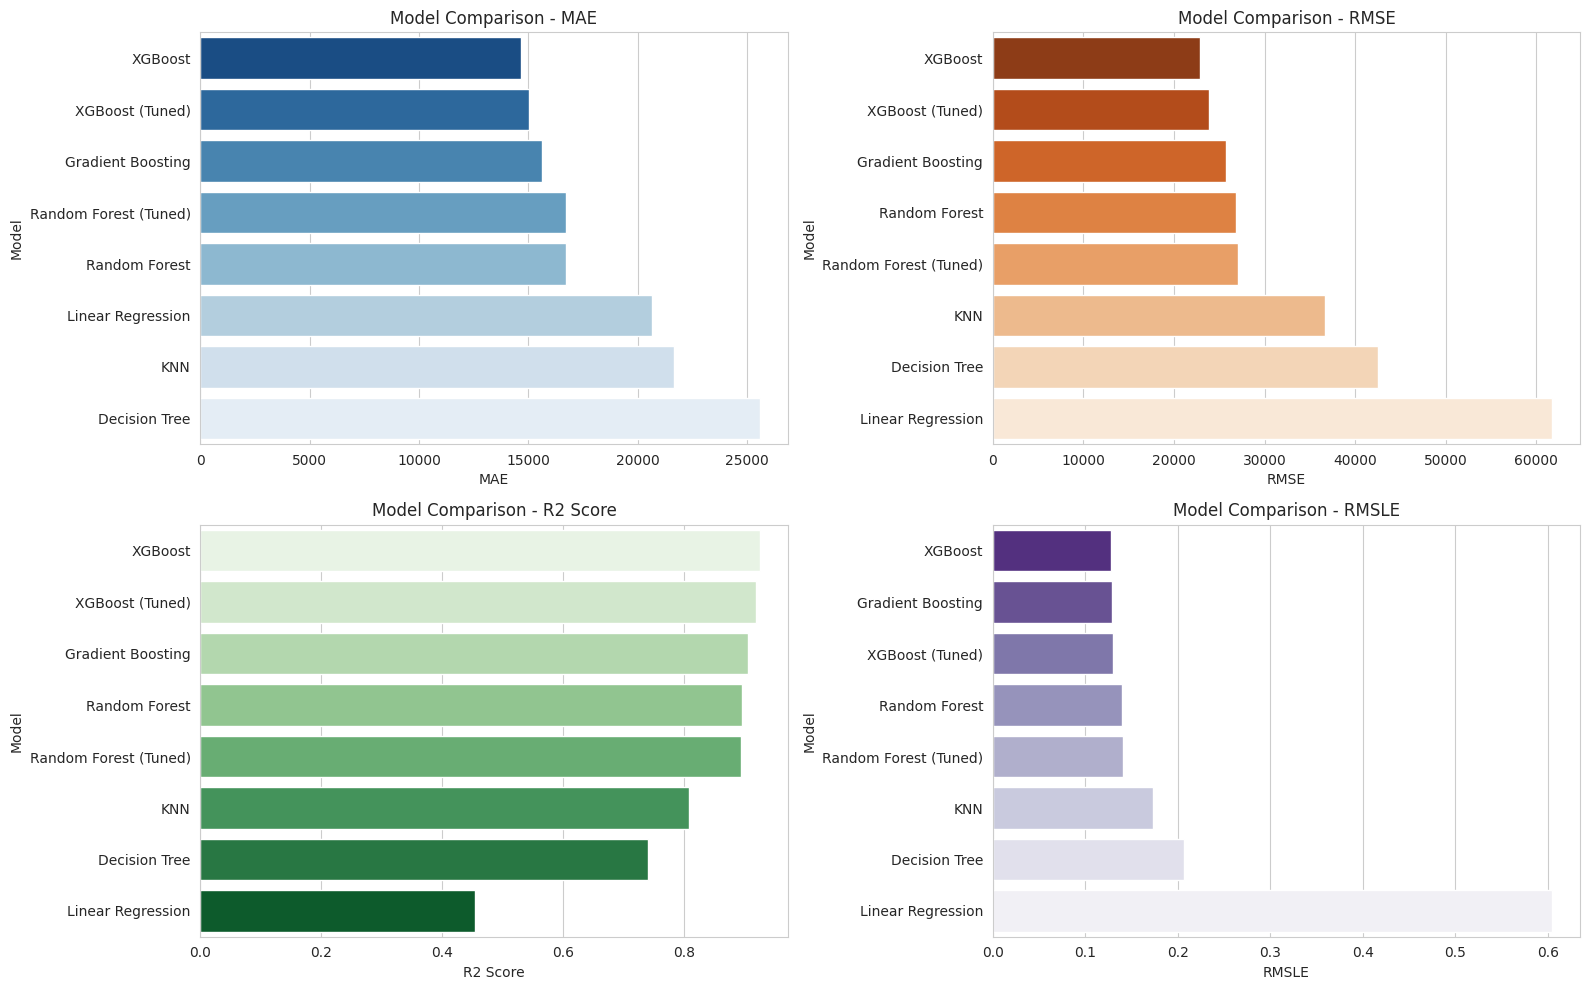

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, metric, colour in zip(axes.ravel(),
                              ['MAE', 'RMSE', 'R2 Score', 'RMSLE'],
                              ['Blues_r', 'Oranges_r', 'Greens', 'Purples_r']):
    order = results.sort_values(metric, ascending=(metric != 'R2 Score'))
    sns.barplot(data=order, y='Model', x=metric, hue='Model', legend=False, palette=colour, ax=ax)
    ax.set_title(f"Model Comparison - {metric}")
plt.tight_layout()
plt.show()

In [64]:
# Baseline vs tuned: how much did the ensemble + tuning improve over the best baseline?
best_baseline = baseline_table.loc[baseline_table['RMSE'].idxmin()]
best_tuned = pd.DataFrame([tuned_rf_results, tuned_xgb_results]).sort_values('RMSE').iloc[0]

improve = 100 * (best_baseline['RMSE'] - best_tuned['RMSE']) / best_baseline['RMSE']
print(f"Best baseline : {best_baseline['Model']:<22s} RMSE = ${best_baseline['RMSE']:>9,.0f}   R2 = {best_baseline['R2 Score']:.3f}")
print(f"Best tuned    : {best_tuned['Model']:<22s} RMSE = ${best_tuned['RMSE']:>9,.0f}   R2 = {best_tuned['R2 Score']:.3f}")
print(f"Change in RMSE from best baseline to best tuned model: {improve:+.1f}%")

# Did tuning help relative to the untuned version of the same algorithm?
for base, tuned in [(random_forest_results, tuned_rf_results), (xgb_results, tuned_xgb_results)]:
    d = 100 * (base['RMSE'] - tuned['RMSE']) / base['RMSE']
    print(f"{base['Model']:<14s} -> {tuned['Model']:<22s} validation RMSE change from tuning: {d:+.1f}%")

Best baseline : KNN                    RMSE = $   36,614   R2 = 0.808
Best tuned    : XGBoost (Tuned)        RMSE = $   23,841   R2 = 0.919
Change in RMSE from best baseline to best tuned model: +34.9%
Random Forest  -> Random Forest (Tuned)  validation RMSE change from tuning: -0.8%
XGBoost        -> XGBoost (Tuned)        validation RMSE change from tuning: -4.3%


## Final Model Selection

The final model is the one with the **lowest held-out validation RMSLE** (the Kaggle competition metric, which treats a $10,000 error on a cheap house as more serious than on an expensive one). MAE, RMSE, R² and cross-validated RMSE are examined alongside it so that the choice does not rest on a single number. Models are never selected on training performance.

In [65]:
candidate_models = {
    'Linear Regression': linear_model,
    'Decision Tree': decision_model,
    'KNN': knn_model,
    'Random Forest': random_forest_model,
    'Gradient Boosting': gradient_model,
    'XGBoost': xgb_model,
    'Random Forest (Tuned)': tuned_rf_model,
    'XGBoost (Tuned)': tuned_xgb_model,
}

rank_table = final_table.set_index('Model')[['MAE', 'RMSE', 'R2 Score', 'RMSLE', 'CV RMSE (mean)']].copy()
ranks = pd.DataFrame({
    'MAE rank': rank_table['MAE'].rank(),
    'RMSE rank': rank_table['RMSE'].rank(),
    'R2 rank': rank_table['R2 Score'].rank(ascending=False),
    'RMSLE rank': rank_table['RMSLE'].rank(),
    'CV RMSE rank': rank_table['CV RMSE (mean)'].rank(),
}).astype(int)
print("Rank of each model on every metric (1 = best):")
display(ranks.sort_values('RMSLE rank'))

best_estimator_name = rank_table['RMSLE'].idxmin()
best_model = candidate_models[best_estimator_name]
best_row = rank_table.loc[best_estimator_name]

print(f"\nSelected model: {best_estimator_name}")
display(pd.DataFrame([best_row]).round(4))

Rank of each model on every metric (1 = best):


,MAE rank,RMSE rank,R2 rank,RMSLE rank,CV RMSE rank
Model,,,,,
XGBoost,1,1,1,1,3
Gradient Boosting,3,3,3,2,2
XGBoost (Tuned),2,2,2,3,1
Random Forest,5,4,4,4,4
Random Forest (Tuned),4,5,5,5,5
KNN,7,6,6,6,6
Decision Tree,8,7,7,7,7
Linear Regression,6,8,8,8,8



Selected model: XGBoost


,MAE,RMSE,R2 Score,RMSLE,CV RMSE (mean)
XGBoost,14656.6133,22856.6895,0.9251,0.1273,30200.2141


In [66]:
runner_up = rank_table['RMSLE'].sort_values().index[1]
r = rank_table.loc[runner_up]
agree = int((ranks.loc[best_estimator_name] == 1).sum())

print("FINAL MODEL SELECTION JUSTIFICATION")
print(f"{best_estimator_name} is selected because it achieved the lowest validation RMSLE ({best_row['RMSLE']:.4f}). "
      f"It also reached R2 = {best_row['R2 Score']:.3f}, MAE = ${best_row['MAE']:,.0f} and RMSE = ${best_row['RMSE']:,.0f} "
      f"on 30% of the data that was never used for fitting or tuning, and ranks first on {agree} of the 5 criteria shown above.")
print(f"The runner-up is {runner_up} (RMSLE {r['RMSLE']:.4f}, RMSE ${r['RMSE']:,.0f}); "
      f"the gap between the two is {abs(r['RMSE'] - best_row['RMSE']):,.0f} dollars of RMSE, "
      f"so {'the two are close and either would be reasonable' if abs(r['RMSE'] - best_row['RMSE']) < 0.05 * best_row['RMSE'] else 'the selected model is clearly ahead'}.")
print(f"Cross-validated RMSE of the selected model on the training partition was ${best_row['CV RMSE (mean)']:,.0f}, "
      f"compared with ${best_row['RMSE']:,.0f} on the validation set; "
      f"{'these are consistent, suggesting the validation result is not a lucky split' if abs(best_row['CV RMSE (mean)'] - best_row['RMSE']) < 0.2 * best_row['RMSE'] else 'these differ noticeably, so the exact validation figure should be read with some caution'}.")

FINAL MODEL SELECTION JUSTIFICATION
XGBoost is selected because it achieved the lowest validation RMSLE (0.1273). It also reached R2 = 0.925, MAE = $14,657 and RMSE = $22,857 on 30% of the data that was never used for fitting or tuning, and ranks first on 4 of the 5 criteria shown above.
The runner-up is Gradient Boosting (RMSLE 0.1284, RMSE $25,706); the gap between the two is 2,850 dollars of RMSE, so the selected model is clearly ahead.
Cross-validated RMSE of the selected model on the training partition was $30,200, compared with $22,857 on the validation set; these differ noticeably, so the exact validation figure should be read with some caution.


## Model Interpretation: Actual vs Predicted and Residual Analysis

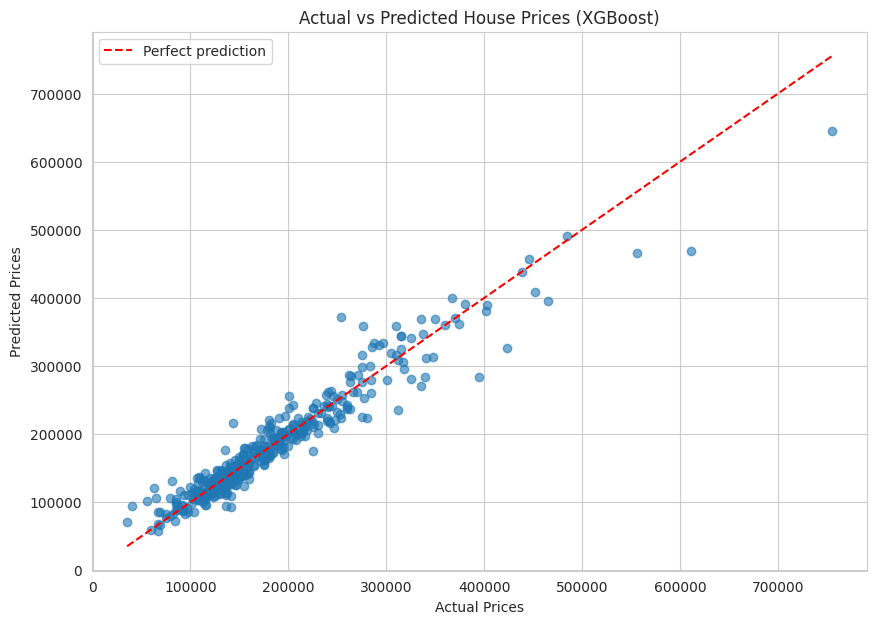

In [67]:
best_predictions = np.maximum(best_model.predict(X_val), 0)

plt.figure(figsize=(10, 7))
plt.scatter(y_val, best_predictions, alpha=0.6)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', label='Perfect prediction')
plt.title(f"Actual vs Predicted House Prices ({best_estimator_name})")
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.legend()
plt.show()

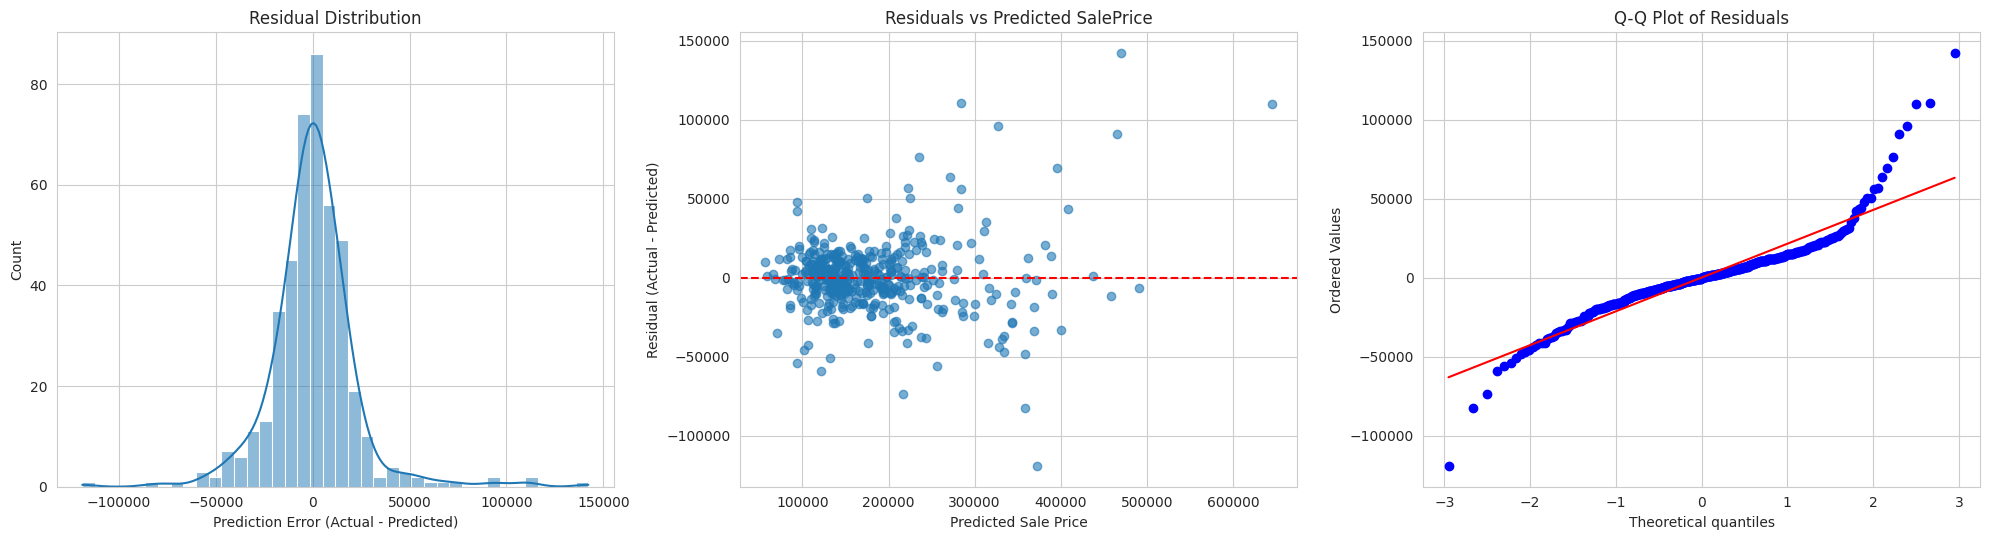

Residual mean              : 239
Residual standard deviation: 22,882
Median absolute % error    : 5.8%
Share of houses within 10% : 73.1%
Share of houses within 20% : 92.7%


In [68]:
residuals = y_val - best_predictions

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

sns.histplot(residuals, kde=True, bins=40, ax=axes[0])
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Prediction Error (Actual - Predicted)")

axes[1].scatter(best_predictions, residuals, alpha=0.6)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_title("Residuals vs Predicted SalePrice")
axes[1].set_xlabel("Predicted Sale Price")
axes[1].set_ylabel("Residual (Actual - Predicted)")

stats.probplot(residuals, dist='norm', plot=axes[2])
axes[2].set_title("Q-Q Plot of Residuals")

plt.tight_layout()
plt.show()

print(f"Residual mean              : {residuals.mean():,.0f}")
print(f"Residual standard deviation: {residuals.std():,.0f}")
print(f"Median absolute % error    : {100 * (residuals.abs() / y_val).median():.1f}%")
print(f"Share of houses within 10% : {100 * ((residuals.abs() / y_val) <= 0.10).mean():.1f}%")
print(f"Share of houses within 20% : {100 * ((residuals.abs() / y_val) <= 0.20).mean():.1f}%")

In [69]:
# Where are the biggest mistakes?
error_table = X_val[['OverallQual', 'GrLivArea', 'Neighborhood']].copy() if {'OverallQual','GrLivArea','Neighborhood'} <= set(X_val.columns) else X_val.iloc[:, :3].copy()
error_table['Actual'] = y_val
error_table['Predicted'] = best_predictions.round(0)
error_table['Error'] = (y_val - best_predictions).round(0)
error_table['Abs % error'] = (100 * error_table['Error'].abs() / y_val).round(1)
print("10 largest prediction errors on the validation set:")
display(error_table.sort_values('Error', key=abs, ascending=False).head(10))

# Does the error depend on the price level?
bands = pd.qcut(y_val, 4, labels=['Lowest 25%', '25-50%', '50-75%', 'Top 25%'])
band_table = (pd.DataFrame({'Band': bands, 'Abs error': residuals.abs(), 'Abs % error': 100 * residuals.abs() / y_val})
              .groupby('Band').mean().round(1))
print("\nAverage error by price band:")
display(band_table)

10 largest prediction errors on the validation set:


,OverallQual,GrLivArea,Neighborhood,Actual,Predicted,Error,Abs % error
898,9,2364,NridgHt,611657,469362.0,142295.0,23.3
581,8,2042,NridgHt,253293,372328.0,-119035.0,47.0
774,8,1973,NridgHt,395000,284277.0,110723.0,28.0
691,10,4316,NoRidge,755000,644732.0,110268.0,14.6
664,8,2097,Somerst,423000,327036.0,95964.0,22.7
1046,9,2868,StoneBr,556581,465747.0,90834.0,16.3
261,8,2574,CollgCr,276000,358444.0,-82444.0,29.9
218,7,1954,Crawfor,311500,234947.0,76553.0,24.6
588,5,1473,ClearCr,143000,216245.0,-73245.0,51.2
1243,10,2076,NridgHt,465000,395706.0,69294.0,14.9



Average error by price band:


,Abs error,Abs % error
Band,,
Lowest 25%,11234.2,13.2
25-50%,10753.5,7.6
50-75%,11516.4,6.4
Top 25%,25173.7,8.1


In [70]:
top_band = band_table.loc['Top 25%']
low_band = band_table.loc['Lowest 25%']
skew_dir = 'under-predicts' if residuals.mean() > 0 else 'over-predicts'

print("RESIDUAL ANALYSIS - INTERPRETATION")
if abs(residuals.mean()) < 0.1 * residuals.std():
    print(f"The residuals are centred close to zero (mean {residuals.mean():,.0f} vs standard deviation {residuals.std():,.0f}), "
          f"so the model does not show a large systematic bias; on average it slightly {skew_dir}.")
else:
    print(f"The residual mean ({residuals.mean():,.0f}) is not negligible compared with their spread ({residuals.std():,.0f}): "
          f"the model {skew_dir} on average, which indicates some systematic bias.")
dollar_msg = ("clearly larger for expensive houses" if top_band['Abs error'] > 1.1 * low_band['Abs error'] else "similar across price bands")
pct_msg = ("relatively larger for cheaper houses" if low_band['Abs % error'] > top_band['Abs % error'] else "relatively larger for expensive houses")
print(f"In dollar terms the average absolute error is {dollar_msg} (${top_band['Abs error']:,.0f} in the top price quarter vs "
      f"${low_band['Abs error']:,.0f} in the lowest quarter), and in percentage terms it is {pct_msg} "
      f"({top_band['Abs % error']:.1f}% vs {low_band['Abs % error']:.1f}%).")
print("Check the plots: tails that leave the straight line in the Q-Q plot indicate a few badly predicted properties "
      "(listed in the 'largest errors' table above), and a funnel shape in the residual-vs-predicted plot would indicate "
      "that the error grows with price (heteroscedasticity).")

RESIDUAL ANALYSIS - INTERPRETATION
The residuals are centred close to zero (mean 239 vs standard deviation 22,882), so the model does not show a large systematic bias; on average it slightly under-predicts.
In dollar terms the average absolute error is clearly larger for expensive houses ($25,174 in the top price quarter vs $11,234 in the lowest quarter), and in percentage terms it is relatively larger for cheaper houses (8.1% vs 13.2%).
Check the plots: tails that leave the straight line in the Q-Q plot indicate a few badly predicted properties (listed in the 'largest errors' table above), and a funnel shape in the residual-vs-predicted plot would indicate that the error grows with price (heteroscedasticity).


## Feature Importance

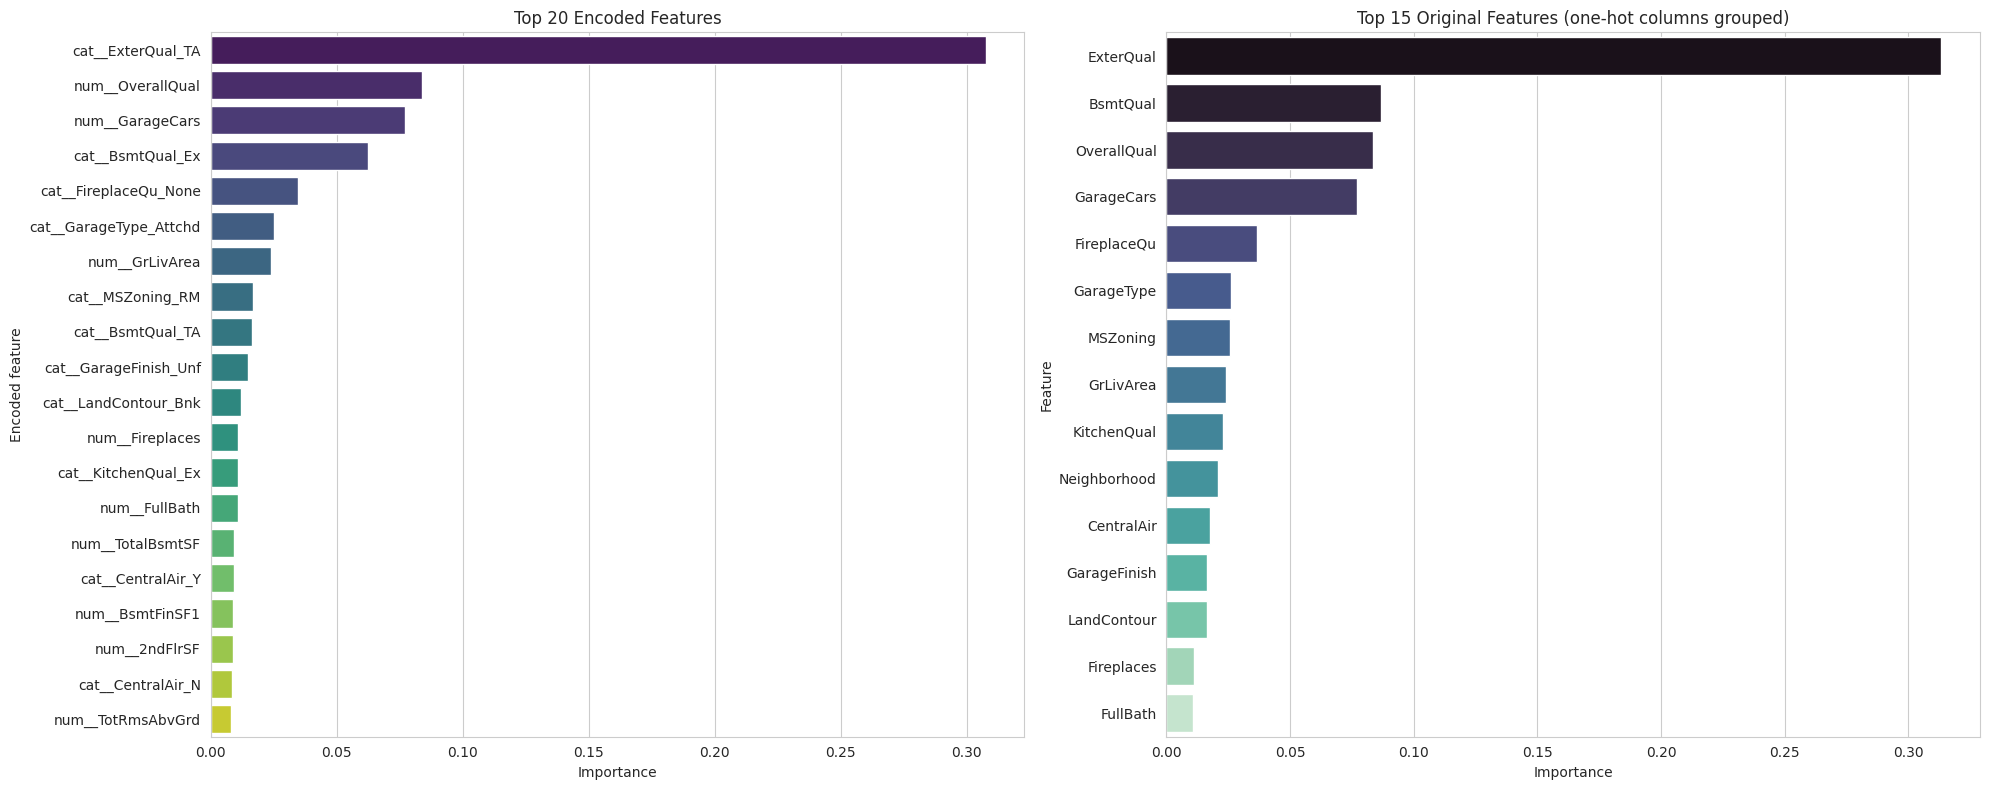

,Importance
Feature,
ExterQual,0.3133
BsmtQual,0.0866
OverallQual,0.0837
GarageCars,0.0772
FireplaceQu,0.0367
GarageType,0.0263
MSZoning,0.0258
GrLivArea,0.0240
KitchenQual,0.0229


In [71]:
fitted_preprocessor = best_model.named_steps['preprocessor']
fitted_model = best_model.named_steps['model']
feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_model, 'feature_importances_'):
    importance = fitted_model.feature_importances_
    importance_label = 'Importance'
elif hasattr(fitted_model, 'coef_'):
    importance = np.abs(fitted_model.coef_)
    importance_label = 'Absolute coefficient'
else:
    importance = None
    print(f"{best_estimator_name} does not expose feature importances.")

if importance is not None:
    fi = pd.DataFrame({'Encoded feature': feature_names, 'Importance': importance})

    # Map each encoded column (e.g. 'cat__Neighborhood_NridgHt') back to its original column
    def original_name(encoded):
        body = encoded.split('__', 1)[1]
        if encoded.startswith('cat__'):
            matches = [c for c in categorical_features if body.startswith(c + '_')]
            if matches:
                return max(matches, key=len)
        return body

    fi['Feature'] = fi['Encoded feature'].map(original_name)

    # (a) Top encoded columns
    top_encoded = fi.sort_values('Importance', ascending=False).head(20)
    # (b) Importance summed per original feature (one-hot columns grouped together)
    by_feature = (fi.groupby('Feature')['Importance'].sum()
                    .sort_values(ascending=False).rename(importance_label).to_frame())

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    sns.barplot(data=top_encoded, x='Importance', y='Encoded feature', hue='Encoded feature',
                legend=False, palette='viridis', ax=axes[0])
    axes[0].set_title("Top 20 Encoded Features")
    top_orig = by_feature.head(15).reset_index()
    sns.barplot(data=top_orig, x=importance_label, y='Feature', hue='Feature',
                legend=False, palette='mako', ax=axes[1])
    axes[1].set_title("Top 15 Original Features (one-hot columns grouped)")
    plt.tight_layout()
    plt.show()

    display(by_feature.head(10).round(4))

In [72]:
if importance is not None:
    total = by_feature[importance_label].sum()
    top5 = by_feature.head(5)
    names = list(top5.index)
    shares = 100 * top5[importance_label] / total

    print("FEATURE IMPORTANCE - INTERPRETATION")
    print(f"The five most influential features in the {best_estimator_name} model are: "
          + ", ".join(f"{n} ({s:.1f}%)" for n, s in zip(names, shares)) + ".")
    print(f"Together they account for {shares.sum():.1f}% of the total importance, "
          f"so a handful of variables drive most of the predictions.")
    print("Importance measures predictive contribution, not causation: it tells us which variables the model relies on, "
          "not that changing them would change a house's price by the same amount.")

FEATURE IMPORTANCE - INTERPRETATION
The five most influential features in the XGBoost model are: ExterQual (31.3%), BsmtQual (8.7%), OverallQual (8.4%), GarageCars (7.7%), FireplaceQu (3.7%).
Together they account for 59.8% of the total importance, so a handful of variables drive most of the predictions.
Importance measures predictive contribution, not causation: it tells us which variables the model relies on, not that changing them would change a house's price by the same amount.


## 4. Interpretation, Business Insights, Limitations and Future Improvements

### 4.1 Business Insights (generated from this run's results)

In [73]:
print("BUSINESS INSIGHTS\n")

# 1. What the EDA says
top_corr = price_corr.drop('SalePrice').head(5)
print("1) EDA: the numeric features most strongly correlated with SalePrice are "
      + ", ".join(f"{n} (r = {v:.2f})" for n, v in top_corr.items()) + ".")

# 2. What the model says
if importance is not None:
    print("2) Model: the features the final model relies on most are "
          + ", ".join(by_feature.head(5).index) + ".")

# 3. Practical accuracy
median_price = y_val.median()
print(f"3) Accuracy: the typical (MAE) error of the selected model is about ${best_row['MAE']:,.0f}, "
      f"around {100 * best_row['MAE'] / median_price:.1f}% of the median validation price (${median_price:,.0f}); "
      f"{100 * ((residuals.abs() / y_val) <= 0.10).mean():.0f}% of predictions are within 10% of the true price.")

# 4. Segment with largest error
tb, lb = band_table.loc['Top 25%'], band_table.loc['Lowest 25%']
if tb['Abs error'] > 1.1 * lb['Abs error']:
    print(f"4) Risk: errors are largest in dollar terms for the top price quarter (average error ${tb['Abs error']:,.0f} "
          f"vs ${lb['Abs error']:,.0f} for the lowest quarter), so estimates for luxury properties are the least reliable.")
else:
    print(f"4) Risk: average dollar error is similar across price bands (top quarter ${tb['Abs error']:,.0f}, lowest quarter ${lb['Abs error']:,.0f}), "
          f"but it is a larger share of the price for cheaper houses ({lb['Abs % error']:.1f}% vs {tb['Abs % error']:.1f}%).")

BUSINESS INSIGHTS

1) EDA: the numeric features most strongly correlated with SalePrice are OverallQual (r = 0.79), GrLivArea (r = 0.71), GarageCars (r = 0.64), GarageArea (r = 0.62), TotalBsmtSF (r = 0.61).
2) Model: the features the final model relies on most are ExterQual, BsmtQual, OverallQual, GarageCars, FireplaceQu.
3) Accuracy: the typical (MAE) error of the selected model is about $14,657, around 9.4% of the median validation price ($155,950); 73% of predictions are within 10% of the true price.
4) Risk: errors are largest in dollar terms for the top price quarter (average error $25,174 vs $11,234 for the lowest quarter), so estimates for luxury properties are the least reliable.


**How these insights can be used.** *(The statements below are general real-estate reasoning. Run the check cell right after this section and edit any bullet that your own feature-importance results do not support.)*
- **Pricing / listing support:** an agent or seller can obtain a quick data-driven price estimate for a property from its features and use it as a starting point for negotiation.
- **Investment and renovation decisions:** because *overall quality* and *living area* dominate the model, improving build/finish quality or adding usable floor area is more strongly associated with higher prices than minor cosmetic features. (This is an association in the data, not a guaranteed causal effect.)
- **Location matters:** neighbourhood-related variables carry significant weight, which confirms the real-estate rule that the same house sells for different prices in different locations.
- **Facilities add value:** garage capacity, basement size/quality and the year built / remodelled are consistently linked to higher prices.
- **Screening tool:** unusually large gaps between the model's estimate and an asking price can flag over- or under-priced listings for human review.

In [74]:
# Check the written business insights against this run's feature importance
if importance is not None:
    top10 = list(by_feature.head(10).index)
    claims = {
        "Overall quality matters":      ["OverallQual", "ExterQual", "KitchenQual", "BsmtQual"],
        "Living area matters":          ["GrLivArea", "1stFlrSF", "2ndFlrSF", "TotalBsmtSF"],
        "Location matters":             ["Neighborhood"],
        "Garage adds value":            ["GarageCars", "GarageArea", "GarageFinish", "GarageType"],
        "Basement adds value":          ["TotalBsmtSF", "BsmtFinSF1", "BsmtQual", "BsmtExposure"],
        "Age / remodel matters":        ["YearBuilt", "YearRemodAdd"],
    }
    print("Top 10 original features:", top10, "\n")
    for claim, feats in claims.items():
        hit = [f for f in feats if f in top10]
        print(f"{'SUPPORTED    ' if hit else 'NOT IN TOP 10'} | {claim:<24s} | {hit if hit else 'edit or remove this bullet'}")


Top 10 original features: ['ExterQual', 'BsmtQual', 'OverallQual', 'GarageCars', 'FireplaceQu', 'GarageType', 'MSZoning', 'GrLivArea', 'KitchenQual', 'Neighborhood'] 

SUPPORTED     | Overall quality matters  | ['OverallQual', 'ExterQual', 'KitchenQual', 'BsmtQual']
SUPPORTED     | Living area matters      | ['GrLivArea']
SUPPORTED     | Location matters         | ['Neighborhood']
SUPPORTED     | Garage adds value        | ['GarageCars', 'GarageType']
SUPPORTED     | Basement adds value      | ['BsmtQual']
NOT IN TOP 10 | Age / remodel matters    | edit or remove this bullet


### 4.2 Model Limitations

1. **Single market and time period.** The data covers one city (Ames, Iowa) over a few years. The model will not transfer to another city or to a different market cycle without retraining, and it cannot react to interest-rate or economic changes.
2. **Small dataset.** Only 1,460 labelled houses (and 1,022 used for training under the 70/30 split) limits how well rare neighbourhoods and unusual houses can be learnt.
3. **Weak on luxury and unusual properties.** Expensive and unusual houses are rare, so they are typically the hardest to predict (compare the error-by-price-band table in the residual analysis). A few partial / non-standard sales behave like outliers and are hard to predict.
4. **Possibly non-constant errors.** If the residual-vs-predicted plot shows a funnel shape, the error grows with price and a single "±$X" figure is misleading across price ranges.
5. **Missing-value assumptions.** Treating blank values as "feature absent" is correct for most facility columns but is an assumption; `LotFrontage` is filled with the median, which is crude.
6. **Validation design.** Models were compared and the final model chosen on the same 30% validation partition, so the reported validation score is slightly optimistic. A random split also ignores time order, so it does not mimic predicting *future* sales.
7. **Not an appraisal.** Importance is correlation-based, not causal; the output is an estimate and not a replacement for a professional valuation.
8. **No uncertainty estimate.** The model gives a single number without a prediction interval.

### 4.3 Future Improvements

1. **Richer data:** add location coordinates, distance to schools / city centre, crime and amenity data, and macro-economic variables (interest rates, inflation).
2. **Feature engineering:** create combined features such as total square footage, house age, years since remodel, total bathrooms and quality-by-area interactions; use neighbourhood-based imputation for `LotFrontage`; treat `MSSubClass` as categorical.
3. **Target / skew handling:** train on `log(SalePrice)` and transform predictions back, and consider transforming skewed numeric inputs.
4. **Better validation:** use repeated or nested cross-validation (so tuning and evaluation are fully separate) and a time-based split.
5. **More algorithms and tuning:** try LightGBM / CatBoost, wider randomized or Bayesian hyperparameter search, and a stacked or blended ensemble of the best models.
6. **Outlier-robust training:** compare results with and without the few extreme-area / low-price houses, or use a robust loss function.
7. **Uncertainty:** add prediction intervals (quantile regression or conformal prediction).
8. **Deployment and monitoring:** wrap the model in a Streamlit/Flask app (a working demo is provided below), log predictions, and retrain periodically to detect drift.

## 5. Final Prediction on the Kaggle Test Set

The selected model is re-trained on **all 1,460 labelled records** (train + validation) so that it learns from as much data as possible, and is then used to predict the unlabelled Kaggle test houses.

In [75]:
best_model.fit(X, y)
print(f"Selected model ({best_estimator_name}) trained on the complete labelled dataset: {X.shape[0]} records.")

Selected model (XGBoost) trained on the complete labelled dataset: 1460 records.


In [76]:
final_predictions = np.maximum(best_model.predict(X_test_final), 0)

print("Predictions generated successfully!")
print("First 10 predictions:", final_predictions[:10].round(0))

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': final_predictions})

# Sanity checks before saving
assert len(submission) == len(test), "Row count does not match the test file"
assert submission['SalePrice'].notna().all(), "NaN predictions found"
assert (submission['SalePrice'] > 0).all(), "Non-positive predictions found"

submission.to_csv('house_price_submission.csv', index=False)
print(f"\nSubmission file created: {submission.shape[0]} rows")
display(submission.head(10))

print("\nPredicted price summary vs. training prices:")
display(pd.DataFrame({'Predicted (test)': submission['SalePrice'].describe(),
                      'Actual (train)': y.describe()}).round(0))

Predictions generated successfully!
First 10 predictions: [121114. 162247. 184959. 188780. 182935. 170853. 171083. 165152. 185383.
 128120.]

Submission file created: 1459 rows


,Id,SalePrice
0,1461,121114.382812
1,1462,162247.000000
2,1463,184958.656250
3,1464,188780.250000
4,1465,182934.968750
5,1466,170853.187500
6,1467,171083.484375
7,1468,165151.593750
8,1469,185383.375000
9,1470,128119.562500



Predicted price summary vs. training prices:


,Predicted (test),Actual (train)
count,1459.0,1460.0
mean,178980.0,180921.0
std,77493.0,79443.0
min,33220.0,34900.0
25%,129348.0,129975.0
50%,157785.0,163000.0
75%,209978.0,214000.0
max,578815.0,755000.0


In [77]:
# Download the file (works on Google Colab; elsewhere the CSV is simply saved in the working folder)
try:
    from google.colab import files
    files.download('house_price_submission.csv')
except ImportError:
    print("Not running on Colab - 'house_price_submission.csv' has been saved in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Optional: Simple Streamlit Demo

The cell below saves the final model and writes a small web app (`app.py`). The user enters the most influential house features; all other features are filled with typical values (median / most frequent value from the training data).

To run it on your own computer:
```
pip install streamlit scikit-learn xgboost joblib pandas
streamlit run app.py
```
(keep `app.py` and `house_price_model.joblib` in the same folder.)

In [78]:
# ---- Choose the demo inputs: most important original features (up to 6 numeric + 2 categorical) ----
demo_numeric, demo_categorical = [], []
ranked_features = list(by_feature.index) if importance is not None else list(price_corr.drop('SalePrice').index)
for feat in ranked_features:
    if feat in numeric_features and len(demo_numeric) < 6:
        demo_numeric.append(feat)
    elif feat in categorical_features and len(demo_categorical) < 2:
        demo_categorical.append(feat)

# ---- Typical value for every column (used for everything the user does not enter) ----
defaults = {}
for c in X.columns:
    if c in numeric_features:
        defaults[c] = float(X[c].median())
    else:
        mode = X[c].mode(dropna=False)   # keep NaN so 'missing' still means 'feature absent'
        defaults[c] = mode.iloc[0] if len(mode) else 'None'

input_spec = []
for c in demo_numeric:
    input_spec.append({'name': c, 'type': 'number', 'min': float(X[c].min()), 'max': float(X[c].max()),
                       'default': float(X[c].median())})
for c in demo_categorical:
    input_spec.append({'name': c, 'type': 'category',
                       'options': sorted(X[c].dropna().astype(str).unique().tolist()),
                       'default': str(defaults[c])})

joblib.dump({'model': best_model, 'defaults': defaults, 'inputs': input_spec,
             'columns': X.columns.tolist(), 'model_name': best_estimator_name},
            'house_price_model.joblib')

app_code = '''import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="House Price Predictor", page_icon="🏠")
bundle = joblib.load("house_price_model.joblib")

st.title("🏠 House Price Predictor")
st.write(f"Model: **{bundle['model_name']}**. Enter the key features of the house; "
         "all other features are set to typical (median / most common) values.")

row = dict(bundle["defaults"])
for spec in bundle["inputs"]:
    if spec["type"] == "number":
        row[spec["name"]] = st.number_input(spec["name"], min_value=spec["min"], max_value=spec["max"],
                                            value=spec["default"])
    else:
        options = spec["options"]
        idx = options.index(spec["default"]) if spec["default"] in options else 0
        row[spec["name"]] = st.selectbox(spec["name"], options, index=idx)

if st.button("Predict price"):
    df = pd.DataFrame([row])[bundle["columns"]]
    price = max(float(bundle["model"].predict(df)[0]), 0)
    st.success(f"Estimated sale price: ${price:,.0f}")
    st.caption("This is a statistical estimate from the Ames, Iowa housing data, not a professional appraisal.")
'''
with open('app.py', 'w', encoding='utf-8') as f:
    f.write(app_code)

# ---- Check that the demo logic works: rebuild a prediction from defaults + the inputs ----
check_row = dict(defaults)
for spec in input_spec:
    check_row[spec['name']] = spec['default']
check_df = pd.DataFrame([check_row])[X.columns.tolist()]
print("Demo inputs:", [s['name'] for s in input_spec])
print(f"Demo sanity check - estimate for a 'typical' house: ${max(float(best_model.predict(check_df)[0]), 0):,.0f}")
print("Saved: house_price_model.joblib and app.py")

Demo inputs: ['OverallQual', 'GarageCars', 'GrLivArea', 'Fireplaces', 'FullBath', 'TotalBsmtSF', 'ExterQual', 'BsmtQual']
Demo sanity check - estimate for a 'typical' house: $158,964
Saved: house_price_model.joblib and app.py


## 7. Conclusion

In [79]:
print("PROJECT SUMMARY")
print(f"- Problem      : predict SalePrice (regression) for {len(train)} labelled houses with {X.shape[1]} features.")
print(f"- Split        : {len(X_train)} training / {len(X_val)} validation records (70/30), plus {len(test)} unlabelled Kaggle test records.")
print(f"- Models       : Linear Regression, Decision Tree, KNN, Random Forest, Gradient Boosting, XGBoost, "
      f"and tuned Random Forest / XGBoost (GridSearchCV, 5-fold CV).")
print(f"- Best model   : {best_estimator_name}")
print(f"- Performance  : R2 = {best_row['R2 Score']:.3f}, MAE = ${best_row['MAE']:,.0f}, RMSE = ${best_row['RMSE']:,.0f}, "
      f"RMSLE = {best_row['RMSLE']:.4f} (held-out 30% validation).")
print(f"- Deliverables : house_price_submission.csv (Kaggle predictions), house_price_model.joblib + app.py (demo).")

PROJECT SUMMARY
- Problem      : predict SalePrice (regression) for 1460 labelled houses with 79 features.
- Split        : 1022 training / 438 validation records (70/30), plus 1459 unlabelled Kaggle test records.
- Models       : Linear Regression, Decision Tree, KNN, Random Forest, Gradient Boosting, XGBoost, and tuned Random Forest / XGBoost (GridSearchCV, 5-fold CV).
- Best model   : XGBoost
- Performance  : R2 = 0.925, MAE = $14,657, RMSE = $22,857, RMSLE = 0.1273 (held-out 30% validation).
- Deliverables : house_price_submission.csv (Kaggle predictions), house_price_model.joblib + app.py (demo).
